# An unbinned analysis of a point source line spectrum

## Introduction

This notebook demonstrates an unbinned spectral analysis of the $1.809\,$MeV line from Al$^{26}$ in the OrEr region, simulated as point source with a Gaussian spectrum.

> **Note:** To keep this tutorial concise, the detailed explanations of the foundational classes (such as `NFResponse`, `NFBackground`, and `UnbinnedThreeMLPointSourceResponseIRFAdaptive`) have been omitted here. If you are unfamiliar with the neural-network response, the background approximation, or the corresponding hardware requirements introduced for DC4, **please refer to the main tutorial:** `example_grb_fit_normalizing_flows.ipynb`. In addition, this notebook is currently part of a draft PR. As such, a more detailed explanation on the newly introduced classes, updates to the already existing classes, will follow. Naming and input conventions may change.

## Imports

This is an optional cell, as it mitigates errors due to too many open files.

In [1]:
import resource

soft, hard = resource.getrlimit(resource.RLIMIT_NOFILE)
new_soft = min(65536, hard)
resource.setrlimit(resource.RLIMIT_NOFILE, (new_soft, hard))
soft, hard = resource.getrlimit(resource.RLIMIT_NOFILE)

In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import healpy as hp
from copy import deepcopy
from pathlib import Path

from cosipy.response.ml import NFNormalizationDensity, NFNormalizationMap
from cosipy.response.ml import NFResponse, UnpolarizedNFFarFieldInstrumentResponseFunction
from cosipy.threeml.ml import UnbinnedThreeMLPointSourceResponseIRFAdaptiveBuckets
from cosipy.event_selection import EnergySelector
from cosipy.background_estimation.ml import NFBkgNormalizationDensity, NFBackground, NFBkgNormalizationMap, FreeNormNFUnbinnedBackground
from cosipy.util import fetch_wasabi_file
from cosipy.spacecraftfile import SpacecraftHistory
from cosipy.threeml.unbinned_model_folding import CachedUnbinnedThreeMLModelFolding
from cosipy.statistics import UnbinnedLikelihood
from cosipy.interfaces import ThreeMLPluginInterface
from cosipy.interfaces.expectation_interface import SumExpectationDensity
from cosipy.data_io.EmCDSUnbinnedData import TimeTagEmCDSEventDataInSCFrameFromDC3Fits
from cosipy.response.relative_irf_hist import IRFRelativeHistUnpolarized

from astropy.time import Time
import astropy.units as u
from threeML import Band, PointSource, Model, JointLikelihood, DataList
from astromodels import Parameter, Powerlaw, Gaussian, SpectralComponent

## Data Selection

In [3]:
USE_NN_RESPONSE = False

In [4]:
data_path = Path(".")

In [5]:
OrEr_data_path = data_path / "OrEr_Al26_tuto_unbinned_data_filtered_with_SAAcut.fits.gz"
fetch_wasabi_file('COSI-SMEX/DC4/Data/Sources/OrEr_Al26_tuto_unbinned_data_filtered_with_SAAcut.fits.gz', 
                  checksum = 'fbf592b4e62e7777988994735ae1559d', output=str(OrEr_data_path))

sc_orientation_path = data_path / "DC4_final_530km_3_month_with_slew_15sbins_GalacticEarth_SAA.ori"
fetch_wasabi_file('COSI-SMEX/DC4/Data/Orientation/DC4_final_530km_3_month_with_slew_15sbins_GalacticEarth_SAA.ori', 
                  checksum = 'bbbe34004153d3a75b051f78cb2a93d9', output=str(sc_orientation_path))

bkg_data_path = data_path / "Total_DC4_BG_3months_unbinned_data_filtered_with_SAAcut_withSAAbck.fits.gz"
fetch_wasabi_file('COSI-SMEX/DC4/Data/Backgrounds/Total_DC4_BG_3months_unbinned_data_filtered_with_SAAcut_withSAAbck.fits.gz', 
                  checksum = '73c8b23e43684da3b35c25499254202b', output=str(bkg_data_path))

bkg_path = data_path / "nfbackground_v2-00.pt"
fetch_wasabi_file('COSI-SMEX/DC4/Data/Responses/nfbackground_v2-00.pt',
                  checksum = '4527aa23ee30bbfc739763a4905a0de6', output=str(bkg_path))

bkg_norm_path = data_path / "1EMD_bkg-nfnormalization-density_v3-00.pt"
fetch_wasabi_file('COSI-SMEX/DC4/Data/Responses/1EMD_bkg-nfnormalization-density_v3-00.pt',
                  checksum = '42d55268bdba9fa670ba8ad22adde2cd', output=str(bkg_norm_path))

if USE_NN_RESPONSE:
    nn_rsp_path = data_path / "unpolarized_nfresponse_v1-01.pt"
    fetch_wasabi_file('COSI-SMEX/DC4/Data/Responses/unpolarized_nfresponse_v1-01.pt',
                      checksum = 'bf2d0c16eac5954fb56489480c2602ca', output=str(nn_rsp_path))
    
    nn_rsp_norm_path = data_path / "unpolarized_1EMD_nfnormalization-density_v2-00.pt"
    fetch_wasabi_file('COSI-SMEX/DC4/Data/Responses/unpolarized_1EMD_nfnormalization-density_v2-00.pt',
                      checksum = '28417f99098c578af0d893008a8e3e83', output=str(nn_rsp_norm_path))
else:
    hist_rsp_path = data_path / "relative_hist_irf_from_nf_response.h5.zip"
    fetch_wasabi_file('COSI-SMEX/develop/Data/Responses/relative_hist_irf_from_nf_response.h5.zip',
                      output=str(hist_rsp_path), checksum = 'd9093daeaf56a386095a42ae40c6635e', unzip=True)
    hist_rsp_path = data_path / "relative_hist_irf_from_nf_response.h5"

A file named OrEr_Al26_tuto_unbinned_data_filtered_with_SAAcut.fits.gz already exists with the specified checksum (fbf592b4e62e7777988994735ae1559d). Skipping.
A file named DC4_final_530km_3_month_with_slew_15sbins_GalacticEarth_SAA.ori already exists with the specified checksum (bbbe34004153d3a75b051f78cb2a93d9). Skipping.
A file named Total_DC4_BG_3months_unbinned_data_filtered_with_SAAcut_withSAAbck.fits.gz already exists with the specified checksum (73c8b23e43684da3b35c25499254202b). Skipping.
A file named nfbackground_v2-00.pt already exists with the specified checksum (4527aa23ee30bbfc739763a4905a0de6). Skipping.
A file named 1EMD_bkg-nfnormalization-density_v3-00.pt already exists with the specified checksum (42d55268bdba9fa670ba8ad22adde2cd). Skipping.


In [6]:
tstart = Time("2028-03-01 01:35:00")
tstop = Time("2028-06-01 10:14:15")
sc_orientation = SpacecraftHistory.open(sc_orientation_path)
sc_orientation = sc_orientation.select_interval(tstart, tstop)

In [7]:
data_file = [OrEr_data_path, bkg_data_path]

energy_range = np.array([1809. - 15, 1809. + 15]) * u.keV
energy_selector = EnergySelector(energy_range)

data = TimeTagEmCDSEventDataInSCFrameFromDC3Fits(data_file, selection=energy_selector)

In [8]:
data.nevents

340961

## Our Model

In [9]:
l =  163.0
b = -22.0 

mu         = 1808.68 *u.keV
sigma      = 3 * u.keV
F          = 3e-4 /u.cm/u.cm/u.s

spectrum =  Gaussian()

spectrum.F.min_value = 1e-6
spectrum.F.max_value = 1e-2

spectrum.mu.min_value = 1800
spectrum.mu.max_value = 1820

spectrum.sigma.min_value = 0.5
spectrum.sigma.max_value = 10

spectrum.F.unit = F.unit
spectrum.F.value = F.value

spectrum.mu.value = mu.value
spectrum.mu.unit = mu.unit

spectrum.sigma.unit = sigma.unit
spectrum.sigma.value = sigma.value
    
spectrum.sigma.free = True
spectrum.mu.free = True
spectrum.F.free = True

source = PointSource("OrEr",
                     l=l,
                     b=b,
                     spectral_shape=spectrum)
model = Model(source)

spectrum_inj = deepcopy(spectrum)

15:30:13 WARNING   The current value of the parameter F (1.0) was above the new maximum 0.01.      ]8;id=355438;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=646881;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter mu (0.0) was below the new minimum 1800.0.   ]8;id=703940;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=836807;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

         WARNING   The current value of the parameter F (1.0) was above the new maximum 0.01.      ]8;id=550953;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=335748;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter mu (0.0) was below the new minimum 1800.0.   ]8;id=105750;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=999127;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

In [10]:
integration_range = np.array([1809. - 15, 1809. + 15]) * u.keV # Can be different than energy_range

## Background

The devices you want to use for the background model, its normalization, and if you choose so, also the response.

In [11]:
devices = ["cuda:0", "cuda:1", "cuda:2", "cuda:3"] # Alternative ["cpu"]

In [12]:
bkg_density_1EMD = NFBkgNormalizationDensity(
    bkg_norm_path,
    show_progress=False,
    density_compile_mode=None,                                          
    devices=devices
)

In [13]:
bkg_model = NFBackground(
    bkg_path,
    density_batch_size=100_000,
    devices=devices,
    density_compile_mode=None,
    show_progress=False
)

bkg = FreeNormNFUnbinnedBackground(
    model=bkg_model, 
    data=data, 
    sc_history=sc_orientation, 
    selection=energy_selector,
    label="bkg_norm"
)

bkg.init_normalization_map(bkg_density_1EMD, Time([tstart, tstop]))

In [14]:
bkg.norm_map.Em_peak_nums = (30, 20)
bkg.norm_map.Em_peaks = [(1809, "w0", "high") if p.energy_keV == 1809 else p for p in bkg.norm_map.Em_peaks]
bkg.norm_map.menergy_keV_resolution = 1.5

In [15]:
bkg.norm_map.init_cache()

In [16]:
bkg.norm_map.cache_to_file(data_path / "OrEr-ptsource_line-tutorial_bkg-norm-cache.h5")

In [17]:
bkg.norm_map.cache_from_file(data_path / "OrEr-ptsource_line-tutorial_bkg-norm-cache.h5")

## Response

### Relative Histogram

In [19]:
if not USE_NN_RESPONSE:
    irf = IRFRelativeHistUnpolarized.from_h5(hist_rsp_path, selections=energy_selector)


WARNING RuntimeWarning: invalid value encountered in divide



### Neural-Network

In [20]:
if USE_NN_RESPONSE:
    rsp_density_1EMD = NFNormalizationDensity(
        nn_rsp_norm_path,
        show_progress=False,
        density_compile_mode=None,                                          
        devices=devices
    )

In [21]:
if USE_NN_RESPONSE:
    rsp = NFResponse(
        nn_rsp_path,
        area_batch_size=200_000,
        density_batch_size=100_000, 
        devices=devices,
        show_progress=False,
        area_compile_mode=None,
        density_compile_mode=None
    )
    
    irf = UnpolarizedNFFarFieldInstrumentResponseFunction(rsp, selection=energy_selector)
    
    irf.init_normalization_map(rsp_density_1EMD, integration_range)

In [22]:
if USE_NN_RESPONSE:
    irf.norm_map.ienergy_keV_resolution = 0.5
    irf.norm_map.Em_peak_nums = (25, 15, 15)
    irf.norm_map.menergy_keV_resolution = 1.

In [23]:
if USE_NN_RESPONSE:
    irf.norm_map.init_cache()

In [24]:
if USE_NN_RESPONSE:
    irf.norm_map.cache_to_file(data_path / "OrEr-ptsource_line-tutorial_irf-norm-cache.h5")

In [25]:
if USE_NN_RESPONSE:
    irf.norm_map.cache_from_file(data_path / "OrEr-ptsource_line-tutorial_irf-norm-cache.h5")

## Folding

In [26]:
psr = UnbinnedThreeMLPointSourceResponseIRFAdaptiveBuckets(
    data=data, 
    irf=irf, 
    sc_history=sc_orientation, 
    show_progress=False,
    force_energy_node_caching=True, 
    reduce_memory=False,
) 

In [27]:
psr._peak_nodes = [[21, 17, 17],]
psr._bkg_nodes  = [[5, 15, 25],]
psr._bkg_thresholds = [[2, 12],]
psr._energy_range = [integration_range.to_value(u.keV).tolist(),]
psr._n_intervals = 1
psr._total_expectation_resolution = 0.1

psr._prepare_integration_structures()

## Fitting

In [28]:
response = CachedUnbinnedThreeMLModelFolding(psr)

In [29]:
expectation_density = SumExpectationDensity(response, bkg)

In [30]:
like_fun = UnbinnedLikelihood(expectation_density)

In [31]:
cosi = ThreeMLPluginInterface('cosi', like_fun, response, bkg)

In [32]:
bkg_norm = bkg.norm.to_value(u.Hz)
    
cosi.bkg_parameter['bkg_norm'] = Parameter("bkg_norm",
                                          bkg_norm,
                                          unit = u.Hz,
                                          min_value=0,
                                          max_value=150,
                                          delta=0.05,)

print(f"The average background flux is {bkg_norm:.2f} Hz")

The average background flux is 0.05 Hz


In [33]:
plugins = DataList(cosi)
like = JointLikelihood(model, plugins, verbose = True)

15:31:49 INFO      set the minimizer to minuit                                             ]8;id=902402;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=878094;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

In [34]:
print(f"Data Events: {data.nevents}\nExpected Events: {expectation_density.expected_counts():.2f}\nRelative Deviation {100 * (expectation_density.expected_counts()/data.nevents - 1):.3f} %")

Data Events: 340961
Expected Events: 341758.25
Relative Deviation 0.234 %


In [35]:
like.fit()

15:32:57 INFO      trial values: 0.0003,1808.7,3,0.048868 -> logL = -3603148.057            ]8;id=298226;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=949286;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#986\986]8;;\

         INFO      trial values: 0.00030603,1808.7,3,0.048868 -> logL = -3603136.858        ]8;id=624778;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=597589;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#986\986]8;;\

         INFO      trial values: 0.00029403,1808.7,3,0.048868 -> logL = -3603162.776        ]8;id=141171;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=599159;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#986\986]8;;\

         INFO      trial values: 0.00030421,1808.7,3,0.048868 -> logL = -3603139.863        ]8;id=152941;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=709277;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#986\986]8;;\

         INFO      trial values: 0.00029582,1808.7,3,0.048868 -> logL = -3603157.969        ]8;id=780057;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=75973;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#986\986]8;;\

...

Values of -log(likelihood) at the minimum:

,-log(likelihood)
cosi,3.603104e+06
total,3.603104e+06


Values of statistical measures:

,statistical measures
AIC,7.206216e+06
BIC,7.206259e+06


(                                         value  negative_error  \
 OrEr.spectrum.main.Gaussian.F         0.000324       -0.000004   
 OrEr.spectrum.main.Gaussian.mu     1808.416388       -0.056443   
 OrEr.spectrum.main.Gaussian.sigma     2.867704       -0.085660   
 bkg_norm                              0.048504       -0.000089   
 
                                    positive_error     error         unit  
 OrEr.spectrum.main.Gaussian.F            0.000004  0.000004  1 / (s cm2)  
 OrEr.spectrum.main.Gaussian.mu           0.057078  0.056761          keV  
 OrEr.spectrum.main.Gaussian.sigma        0.085574  0.085617          keV  
 bkg_norm                                 0.000091  0.000090           Hz  ,
        -log(likelihood)
 cosi       3.603104e+06
 total      3.603104e+06)

## Comparison 

In [36]:
results = like.results

parameters = {par.name: results.get_variates(par.path)
              for par in results.optimized_model["OrEr"].parameters.values()
              if par.free}

results_err = results.propagate(results.optimized_model["OrEr"].spectrum.main.shape.evaluate_at, **parameters)

         WARNING   The current value of the parameter F (1.0) was above the new maximum 0.01.      ]8;id=757060;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=111204;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter mu (0.0) was below the new minimum 1800.0.   ]8;id=99413;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=70729;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

         WARNING   The current value of the parameter F (1.0) was above the new maximum 0.01.      ]8;id=327126;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=281481;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter mu (0.0) was below the new minimum 1800.0.   ]8;id=334875;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=910141;file:///localscratch1/pjanowsk/miniconda3/envs/cosipy_main-3.12/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

In [37]:
energy = np.geomspace(integration_range[0], integration_range[1], 150).to_value(u.keV)

flux_lo = np.zeros_like(energy)
flux_median = np.zeros_like(energy)
flux_hi = np.zeros_like(energy)
flux_inj = np.zeros_like(energy)

for i, e in enumerate(energy):
    flux = results_err(e)
    flux_median[i] = flux.median
    flux_lo[i], flux_hi[i] = flux.equal_tail_interval(cl=0.68)
    flux_inj[i] = spectrum_inj.evaluate_at(e)

In [38]:
%matplotlib inline

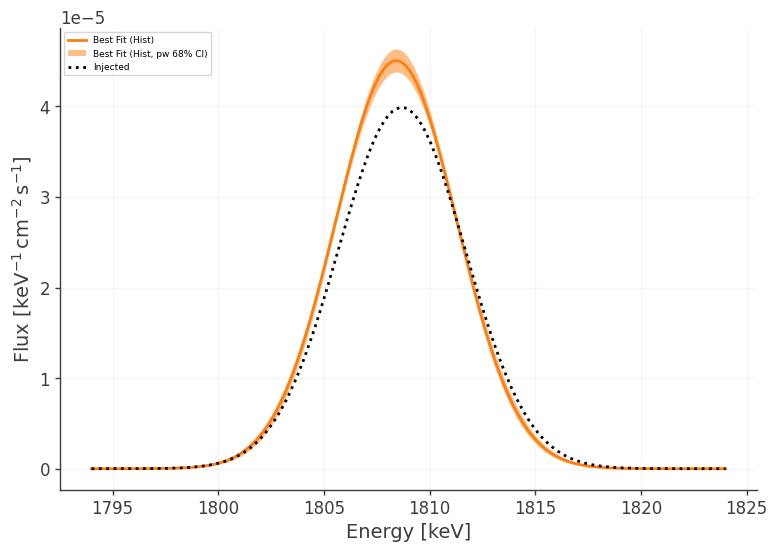

In [41]:
fig, ax = plt.subplots(figsize = (9, 6))

if USE_NN_RESPONSE:
    lbl = "NN"
    col = "tab:blue"
else:
    lbl = "Hist"
    col = "tab:orange"

ax.plot(energy, flux_median, color=col, label = f"Best Fit ({lbl})")
ax.fill_between(energy, flux_lo, flux_hi, alpha=.5, lw=0, color=col, label = f"Best Fit ({lbl}, pw 68% CI)")
ax.plot(energy, flux_inj, color = 'black', ls = ":", label = "Injected")

ax.set_xlabel(r"Energy [keV]")
ax.set_ylabel(r"Flux [$\mathrm{keV^{-1}\,cm^{-2}\,s^{-1}}$]")

ax.grid(which="both", linewidth=1.0, alpha=0.25, color="0.85")
ax.legend(fontsize=6.5, loc="upper left");